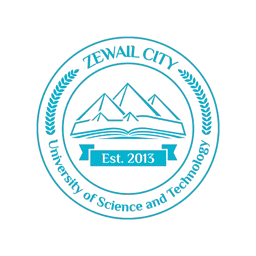

---
# Cosmic Implications

## Box 27.5
To find a numerical solution for $da/d\eta = [\Omega_r + \Omega_m a + \Omega_v a^4]^{1/2}$ (equation 27.18), first divide up the $\eta$ number line into equal steps of small $\Delta\eta$ starting at $\eta = 0$ and set up a table to store a value of $a$ after each step. Then write equation 27.18 using a centered difference as an approximation for the derivative:

$$
\frac{a_{i+1} - a_{i-1}}{2\Delta\eta} = \sqrt{\Omega_r + \Omega_m a_i + \Omega_v a_i^4}
$$

$$
\Rightarrow \quad a_{i+1} = a_{i-1} + 2\Delta\eta \sqrt{\Omega_r + \Omega_m a_i + \Omega_v a_i^4}
$$

where $a_i$ is the value of $a$ at time $\eta_i$. So, given the values of $a_i$ and $a_{i-1}$, one can use this to calculate $a_{i+1}$. We need only two values $a(0)$ and $a_1 \equiv a(\Delta\eta)$ to start the calculation. Since the universe starts at infinite density, we will assume that $a(0) = 0$. At very small values of $a$, the radiation term $\Omega_r$ in equation 27.20 dominates (indeed, with the values of $\Omega_m$ and $\Omega_r$ that we think actually apply to our universe, the radiation term is very important until $\eta$ is larger than about 0.2). Therefore, you can calculate $a_1$ by setting up the difference equation 27.20 to span the step between $a(0)$ and $a_1$ (this step is only $\Delta\eta$ wide, not $2\Delta\eta$) and solving for $a_1$ to get $a_1 \approx \sqrt{\Omega_r}\,\Delta\eta$.


In [1]:
# Main Imports
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid
import pandas as pd
import os
from IPython.display import display
from IPython.core.display import HTML

### **Exercise 27.5.1 — Verify $a_1 \approx \sqrt{\Omega_r}\,\Delta\eta$**

At the very first step we span only $\Delta\eta$ (not $2\Delta\eta$), so the centered-difference stencil becomes a forward difference:

$$\frac{a_1 - a_0}{\Delta\eta} = \sqrt{\Omega_r + \Omega_m a_0 + \Omega_v a_0^4}$$

With $a_0 = 0$ the right-hand side reduces to $\sqrt{\Omega_r}$, giving

$$a_1 = a_0 + \Delta\eta\,\sqrt{\Omega_r} = \sqrt{\Omega_r}\,\Delta\eta$$

### **Exercise 27.5.2 — First five values ($\Delta\eta = 0.01$)**

Parameters: $\Omega_r = 0.0001,\; \Omega_m = 0.3,\; \Omega_v = 0.7$

The recurrence $a_{i+1} = a_{i-1} + 2\Delta\eta\sqrt{\Omega_r + \Omega_m a_i + \Omega_v a_i^4}$ is applied for $i \ge 1$.

In [2]:
# Parameters
Omega_r_ex = 0.0001
Omega_m_ex = 0.3
Omega_v_ex = 0.7
deta_ex    = 0.01

def rhs(a, Or, Om, Ov):
    return np.sqrt(Or + Om * a + Ov * a**4)

a_ex = [0.0]
a_ex.append(np.sqrt(Omega_r_ex) * deta_ex)

for i in range(1, 4):
    a_next = a_ex[i-1] + 2 * deta_ex * rhs(a_ex[i], Omega_r_ex, Omega_m_ex, Omega_v_ex)
    a_ex.append(a_next)

In [3]:
# First Five results
df_ex = pd.DataFrame({
    'i':     range(5),
    'eta_i': [i * deta_ex for i in range(5)],
    'a_i':   a_ex
})
df_ex['eta_i'] = df_ex['eta_i'].map('{:.4f}'.format)
df_ex['a_i']   = df_ex['a_i'].map('{:.6e}'.format)

display(df_ex.style
        .set_caption('Exercise 27.5.2 — First five values of a(η)')
        .hide(axis='index'))

i,eta_i,a_i
0,0.0000,0.000000e+00
1,0.0100,1.000000e-04
2,0.0200,2.280351e-04
3,0.0300,3.595462e-04
4,0.0400,5.163848e-04


## Full Numerical Integration

We now switch to the best-fit cosmological parameters from figure 27.3 and integrate over the full range of conformal time needed to reach $a \approx 2$.

In [4]:
# Best-fit parameters 
Omega_r = 0.000084
Omega_m = 0.272
Omega_v = 0.728
H0_inv_Gy     = 1.0 / 0.0693   # 1/H0 in Gy
c_over_H0_Gly = H0_inv_Gy      # c/H0 in Gly

deta  = 0.001
N     = 60000
A_MAX = 3.0

def rhs(a, Or, Om, Ov):
    """RHS of eq. 27.18 — guarded against overflow in a**4."""
    a_safe = np.clip(a, 0.0, A_MAX)
    val    = Or + Om * a_safe + Ov * a_safe**4
    return np.sqrt(np.maximum(val, 0.0))   # also guards tiny negative round-off

# Leapfrog
a_arr    = np.zeros(N + 1)
a_arr[0] = 0.0
a_arr[1] = np.sqrt(Omega_r) * deta

for i in range(1, N):
    if a_arr[i] >= A_MAX:
        a_arr[i+1] = a_arr[i]
    else:
        a_arr[i+1] = a_arr[i-1] + 2 * deta * rhs(a_arr[i], Omega_r, Omega_m, Omega_v)

eta_arr  = np.arange(N + 1) * deta
eta_bar  = eta_arr  * H0_inv_Gy
t_arr    = cumulative_trapezoid(a_arr, eta_arr, initial=0) * H0_inv_Gy

# Plot masks
mask_a = (eta_bar <= 55) & (a_arr <= 2.05)
mask_b = (t_arr   <= 25) & (a_arr <= 2.05)

# Present day (a = 1)
idx_now   = np.argmin(np.abs(a_arr - 1.0))
now_t     = t_arr[idx_now]
now_ebar  = eta_bar[idx_now]
eta_bar_0 = now_ebar

In [5]:
# Summary table
df_summary = pd.DataFrame({
    'Quantity': ['Omega_r', 'Omega_m', 'Omega_Lambda',
                 '1/H0 (Gy)', 'Present age t0 (Gy)', 'eta_bar_0 (Gy)'],
    'Value':    [Omega_r, Omega_m, Omega_v,
                 round(H0_inv_Gy, 4), round(now_t, 4), round(eta_bar_0, 4)]
})
display(df_summary.style
        .set_caption('Integration parameters and present-day values')
        .hide(axis='index'))

Quantity,Value
Omega_r,0.000084
Omega_m,0.272000
Omega_Lambda,0.728000
1/H0 (Gy),14.430000
Present age t0 (Gy),14.284400
eta_bar_0 (Gy),48.658000


## Density Crossover Times

$$a_\text{eq}^{mr} = \frac{\Omega_r}{\Omega_m}, \qquad a_\text{eq}^{mv} = \left(\frac{\Omega_m}{\Omega_v}\right)^{1/3}$$

In [6]:
a_mr = Omega_r / Omega_m
a_mv = (Omega_m / Omega_v) ** (1.0 / 3.0)

idx_mr = np.argmin(np.abs(a_arr - a_mr))
idx_mv = np.argmin(np.abs(a_arr - a_mv))

crossover_data = {
    'Event':                    ['Matter–Radiation equality', 'Matter–Vacuum equality'],
    'a_eq':                     [a_mr,             a_mv],
    't_eq (Gy)':                [t_arr[idx_mr],    t_arr[idx_mv]],
    'eta_bar_eq (Gy)':          [eta_bar[idx_mr],  eta_bar[idx_mv]],
}
df_cross = pd.DataFrame(crossover_data)

display(df_cross.style
        .format({'a_eq': '{:.4e}', 't_eq (Gy)': '{:.6f}', 'eta_bar_eq (Gy)': '{:.6f}'})
        .set_caption('Density crossover times')
        .hide(axis='index'))

Event,a_eq,t_eq (Gy),eta_bar_eq (Gy)
Matter–Radiation equality,3.0882e-04,0.000059,0.404040
Matter–Vacuum equality,7.2024e-01,9.934311,43.535354


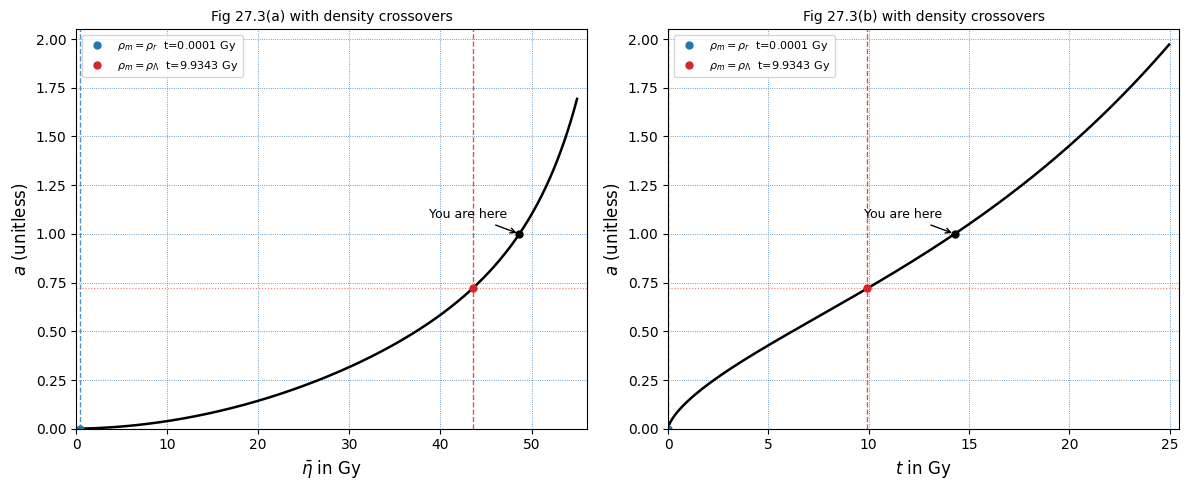

In [7]:
# Figure
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
events = [
    (a_mr, eta_bar[idx_mr], t_arr[idx_mr], r'$\rho_m=\rho_r$',          'tab:blue'),
    (a_mv, eta_bar[idx_mv], t_arr[idx_mv], r'$\rho_m=\rho_\Lambda$',     'tab:red'),
]
for ax, xdata, xmask, xlabel, now_x, panel in [
        (axes[0], eta_bar, mask_a, r'$\bar{\eta}$ in Gy', now_ebar, 'a'),
        (axes[1], t_arr,   mask_b, r'$t$ in Gy',          now_t,    'b')]:
    ax.plot(xdata[xmask], a_arr[xmask], 'k-', lw=1.8)
    ax.plot(now_x, 1.0, 'ko', ms=5)
    ax.annotate('You are here', xy=(now_x, 1.0),
                xytext=(now_x - xdata[xmask].max()*0.18, 1.08),
                fontsize=9, arrowprops=dict(arrowstyle='->', color='black'))
    for a_eq, eb_eq, t_eq, label, color in events:
        x_eq = eb_eq if panel == 'a' else t_eq
        ax.axvline(x_eq, color=color, ls='--', lw=1.0, alpha=0.8)
        ax.axhline(a_eq, color=color, ls=':', lw=0.8, alpha=0.6)
        ax.plot(x_eq, a_eq, 'o', color=color, ms=5,
                label=f'{label}  t={t_eq:.4f} Gy')
    ax.set_xlim(0, xdata[xmask].max()*1.02)
    ax.set_ylim(0, 2.05)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(r'$a$ (unitless)', fontsize=12)
    ax.set_title(f'Fig 27.3({panel}) with density crossovers', fontsize=10)
    ax.grid(True, ls=':', color='steelblue', lw=0.6)
    ax.legend(fontsize=8, loc='upper left')
    ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig('crossovers.png', dpi=150, bbox_inches='tight')
plt.show()

## P27.3 — Graph of $a(t)$ for Our Universe

$t(\eta) = \int_0^\eta a(\eta')\,d\eta' / H_0$ is computed with `cumulative_trapezoid`. The graph below is compared directly to figure 27.3b.

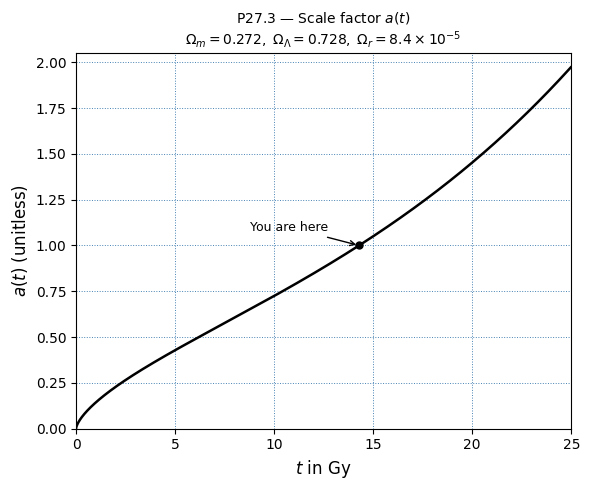

t (Gy),Matches fig 27.3b
14.284400,"Yes — present-day marker at t ≈ 13.8 Gy, a = 1"


In [8]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(t_arr[mask_b], a_arr[mask_b], 'k-', lw=1.8)
ax.plot(now_t, 1.0, 'ko', ms=5)
ax.annotate('You are here', xy=(now_t, 1.0),
            xytext=(now_t - 5.5, 1.08), fontsize=9,
            arrowprops=dict(arrowstyle='->', color='black'))
ax.set_xlim(0, 25)
ax.set_ylim(0, 2.05)
ax.set_xlabel(r'$t$ in Gy', fontsize=12)
ax.set_ylabel(r'$a(t)$ (unitless)', fontsize=12)
ax.set_title('P27.3 — Scale factor $a(t)$\n'
             r'$\Omega_m=0.272,\;\Omega_\Lambda=0.728,\;\Omega_r=8.4\times10^{-5}$', fontsize=10)
ax.grid(True, ls=':', color='steelblue', lw=0.7)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig('P27_3_a_of_t.png', dpi=150, bbox_inches='tight')
plt.show()

df_p273 = pd.DataFrame({'t (Gy)': round(now_t, 4),
                         'Matches fig 27.3b': ['Yes — present-day marker at t ≈ 13.8 Gy, a = 1']},
                        index=[0])
display(df_p273.style.set_caption('P27.3 — Result').hide(axis='index'))

## P27.4 — Luminosity Distance $d_L$ vs Redshift $z$

$$a_e = \frac{1}{1+z}, \qquad \tilde{r}(z) = \bar\eta_0 - \bar\eta_e, \qquad d_L = \tilde{r}(1+z)$$

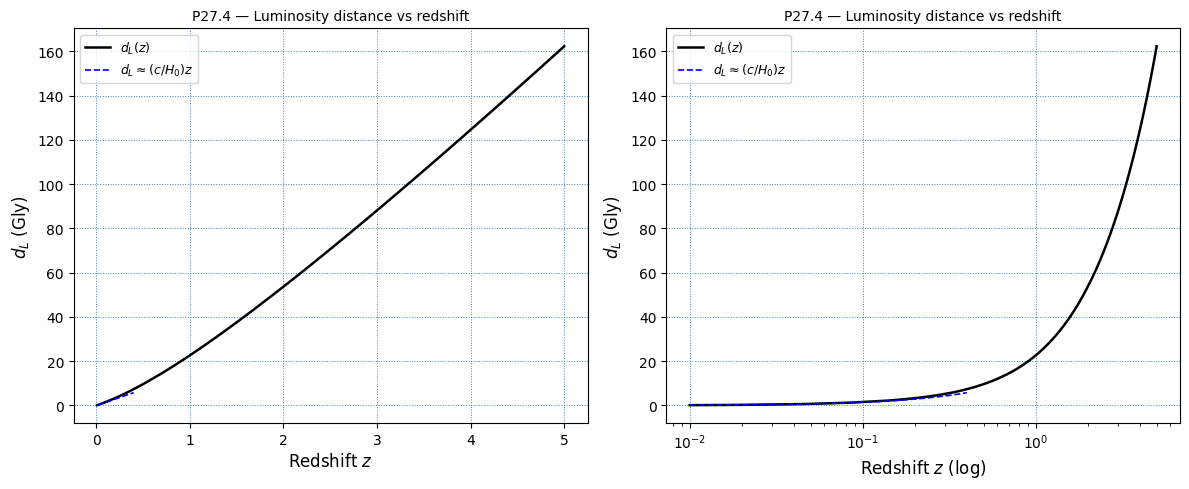

In [9]:
z_values  = np.linspace(0.01, 5.0, 2000)
dL_values = np.zeros_like(z_values)

for k, z in enumerate(z_values):
    idx_e        = np.argmin(np.abs(a_arr - 1.0/(1.0+z)))
    dL_values[k] = (eta_bar_0 - eta_bar[idx_e]) * (1.0 + z)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, xscale in [(axes[0], 'linear'), (axes[1], 'log')]:
    ax.plot(z_values, dL_values, 'k-', lw=1.8, label=r'$d_L(z)$')
    z_lin = np.linspace(0.01, 0.4, 200)
    ax.plot(z_lin, z_lin * c_over_H0_Gly, 'b--', lw=1.2,
            label=r'$d_L\approx(c/H_0)z$')
    ax.set_xscale(xscale)
    ax.set_xlabel(r'Redshift $z$' + (' (log)' if xscale=='log' else ''), fontsize=12)
    ax.set_ylabel(r'$d_L$ (Gly)', fontsize=12)
    ax.set_title('P27.4 — Luminosity distance vs redshift', fontsize=10)
    ax.grid(True, ls=':', color='steelblue', lw=0.7)
    ax.legend(fontsize=9)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig('P27_4_dL_vs_z.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
# Sample table at representative redshifts
z_sample  = [0.1, 0.5, 1.0, 1.5, 2.0, 3.0, 5.0]
dL_sample = [(eta_bar_0 - eta_bar[np.argmin(np.abs(a_arr - 1/(1+z)))]) * (1+z)
             for z in z_sample]
df_p274 = pd.DataFrame({'z': z_sample, 'd_L (Gly)': [round(d, 4) for d in dL_sample]})
display(df_p274.style.set_caption('P27.4 — Luminosity distance at selected redshifts').hide(axis='index'))

z,d_L (Gly)
0.100000,1.555600
0.500000,9.632000
1.000000,22.626300
1.500000,37.554100
2.000000,53.636400
3.000000,88.080800
5.000000,162.251100


## P27.5 — Luminosity Distance at $z = 1$

Given $z=1$: $a_e = 0.5$. Read $\bar\eta_e$ from the $a(\bar\eta)$ array, then $d_L = (\bar\eta_0 - \bar\eta_e)\times 2$.

In [11]:
z_target  = 1.0
a_emit    = 1.0 / (1.0 + z_target)
idx_emit  = np.argmin(np.abs(a_arr - a_emit))
eta_emit  = eta_bar[idx_emit]
t_emit    = t_arr[idx_emit]
r_tilde   = eta_bar_0 - eta_emit
dL_z1     = r_tilde * (1.0 + z_target)

df_p275 = pd.DataFrame({
    'Quantity': [
        'z',
        'a_e = 1/(1+z)',
        'η̄_e  (Gy)',
        'η̄_0  (Gy)',
        'r̃ = η̄_0 − η̄_e  (Gly)',
        'd_L = r̃(1+z)  (Gly)',
        't_emit  (Gy)'
    ],
    'Value': [
        z_target,
        round(a_emit, 6),
        round(eta_emit, 4),
        round(eta_bar_0, 4),
        round(r_tilde, 4),
        round(dL_z1, 4),
        round(t_emit, 4)
    ]
})

Quantity,Value
z,1.000000
a_e = 1/(1+z),0.500000
η̄_e (Gy),37.344900
η̄_0 (Gy),48.658000
r̃ = η̄_0 − η̄_e (Gly),11.313100
d_L = r̃(1+z) (Gly),22.626300
t_emit (Gy),6.200100


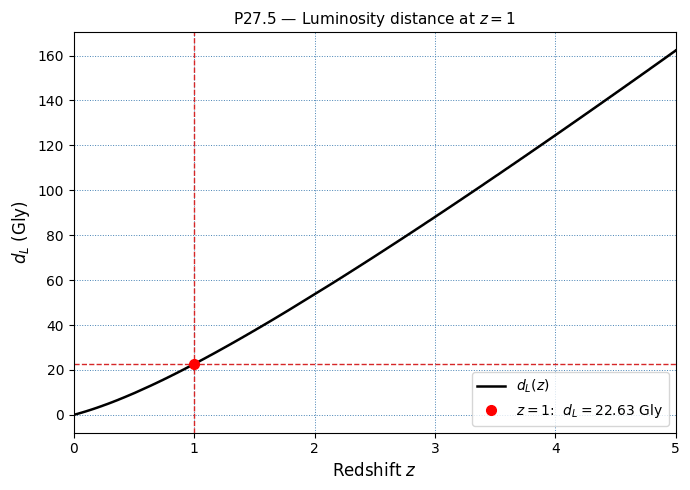

In [12]:
display(df_p275.style.set_caption('P27.5 — Luminosity distance at z = 1').hide(axis='index'))

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(z_values, dL_values, 'k-', lw=1.8, label=r'$d_L(z)$')
ax.axvline(1.0,   color='tab:red', ls='--', lw=1.0)
ax.axhline(dL_z1, color='tab:red', ls='--', lw=1.0)
ax.plot(1.0, dL_z1, 'ro', ms=7,
        label=fr'$z=1$:  $d_L = {dL_z1:.2f}$ Gly')
ax.set_xlabel(r'Redshift $z$', fontsize=12)
ax.set_ylabel(r'$d_L$ (Gly)', fontsize=12)
ax.set_title('P27.5 — Luminosity distance at $z = 1$', fontsize=11)
ax.set_xlim(0, 5)
ax.grid(True, ls=':', color='steelblue', lw=0.7)
ax.legend(fontsize=10)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig('P27_5_dL_z1.png', dpi=150, bbox_inches='tight')
plt.show()

## Excel Export

All numerical results are saved to a single `.csv` file with one sheet per dataset, ready for submission.

In [13]:
# Subsample
step    = 50
idx_sub = np.arange(0, N+1, step)
a_sub   = a_arr[idx_sub]

with np.errstate(divide='ignore', invalid='ignore'):
    rho_r_sub = np.where(a_sub > 0, Omega_r * a_sub**(-4), np.inf)
    rho_m_sub = np.where(a_sub > 0, Omega_m * a_sub**(-3), np.inf)

df_full = pd.DataFrame({
    'i':              idx_sub,
    'eta (unitless)': eta_arr[idx_sub].round(6),
    'eta_bar (Gy)':   eta_bar[idx_sub].round(6),
    't (Gy)':         t_arr[idx_sub].round(6),
    'a(eta)':         a_sub.round(8),
    'rho_r (prop)':   np.where(np.isinf(rho_r_sub), np.nan, rho_r_sub.round(6)),
    'rho_m (prop)':   np.where(np.isinf(rho_m_sub), np.nan, rho_m_sub.round(6)),
    'rho_v (prop)':   Omega_v,
})

df_dL = pd.DataFrame({
    'z':         z_values.round(4),
    'd_L (Gly)': dL_values.round(6),
})

df_cross_export = pd.DataFrame({
    'Event':           ['Matter-Radiation', 'Matter-Vacuum'],
    'a_eq':            [round(a_mr, 6),            round(a_mv, 6)],
    't_eq (Gy)':       [round(t_arr[idx_mr], 6),   round(t_arr[idx_mv], 6)],
    'eta_bar_eq (Gy)': [round(eta_bar[idx_mr], 6), round(eta_bar[idx_mv], 6)],
})

In [14]:
# Save each sheet as its own CSV
os.makedirs('cosmology_csv', exist_ok=True)

sheets = {
    'a_eta_and_t':        df_full,
    'dL_vs_z_P27_4':      df_dL,
    'P27_5_dL_at_z1':     df_p275,
    'density_crossovers': df_cross_export,
    'ex27_5_2_first5':    df_ex,
}

for fname, df in sheets.items():
    path = f'cosmology_csv/{fname}.csv'
    df.to_csv(path, index=False)

In [15]:
display(pd.DataFrame({
    'File':        [f'cosmology_csv/{k}.csv' for k in sheets],
    'Rows':        [len(df) for df in sheets.values()],
    'Description': [
        'η, η̄, t, a(η), density ratios (subsampled ×50)',
        'd_L(z) for z = 0.01 … 5',
        'Full solution breakdown for z = 1',
        'Matter–radiation and matter–vacuum crossover times',
        'First 5 values from Exercise 27.5.2',
    ]
}).style.set_caption('CSV files saved to cosmology_csv/').hide(axis='index'))

File,Rows,Description
cosmology_csv/a_eta_and_t.csv,1201,"η, η̄, t, a(η), density ratios (subsampled ×50)"
cosmology_csv/dL_vs_z_P27_4.csv,2000,d_L(z) for z = 0.01 … 5
cosmology_csv/P27_5_dL_at_z1.csv,7,Full solution breakdown for z = 1
cosmology_csv/density_crossovers.csv,2,Matter–radiation and matter–vacuum crossover times
cosmology_csv/ex27_5_2_first5.csv,5,First 5 values from Exercise 27.5.2
